# Agent 02 · A learning seller against a rule-following seller

**Course:** Intelligent System Development &nbsp;|&nbsp; **Lab:** Experiment 02 &nbsp;|&nbsp; **Author:** Bùi Nguyên Hoàng Việt (B23DCDT285)

---

## What is this notebook about?

Two online shops sell an identical product. Every time step each shop picks one of two moves: **keep the price** or **give a 20 % discount**. A discount draws in more customers, but each sale earns less, and it also pulls customers away from the competitor.

We drop two very different decision makers into this market and compare them:

| Seat | Decision maker | How it decides |
|---|---|---|
| 0 | **Q-learning seller** (reinforcement learning) | starts with a blank table, improves it from the profit it observes |
| 1 | **Rule-based seller** | three fixed *if-then* rules, never changes |

### Roadmap

1. The market and a hand-played step
2. What the model says before any learning (expected profit)
3. The two sellers and the Q-learning update (question 3)
4. Experiments A + B - one baseline run and its learning curve
5. Experiment C - learning rate
6. Experiment D - exploration
7. Experiment E - fair comparison over 10 seeds
8. Question 8 - both sellers learn
9. Question 9 - the rival becomes aggressive
10. Question 10 - a sturdier learner
11. Take-aways

> **Where is the code?** All logic lives in `code/agent02_experiment.py`. This notebook imports it, calls one function per experiment and explains the output. Running the notebook top to bottom takes roughly 25 minutes and regenerates everything in `results/`; the random seeds are fixed, so you get the same numbers as the report.

In [1]:
import csv
import io
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

# locate the project whether the notebook is started from notebook/ or from the root
HERE = Path.cwd()
PROJECT = HERE.parent if HERE.name == "notebook" else HERE
sys.path.insert(0, str(PROJECT / "code"))

import agent02_experiment as lab

cfg = lab.Settings()
for folder in (lab.RESULTS, lab.FIGURES, lab.TABLES):
    folder.mkdir(parents=True, exist_ok=True)
(lab.RESULTS / "q_tables.txt").unlink(missing_ok=True)   # start from a clean log


def show_fig(fig, dpi=130):
    # render a Matplotlib figure into the notebook (the lab module forces the Agg backend)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buf.getvalue()))


def show_png(name):
    display(Image(filename=str(lab.FIGURES / name)))


def print_table(csv_name, columns=None, digits=3):
    # print a results CSV as an aligned text table
    with open(lab.RESULTS / csv_name, encoding="utf-8") as fh:
        records = list(csv.DictReader(fh))
    columns = columns or list(records[0])

    def cell(value):
        try:
            return f"{float(value):.{digits}f}" if "." in value else value
        except ValueError:
            return value

    widths = [max(len(c), *(len(cell(r[c])) for r in records)) for c in columns]
    line = " | ".join("{:<%d}" % w for w in widths)
    print(line.format(*columns))
    print("-+-".join("-" * w for w in widths))
    for r in records:
        print(line.format(*(cell(r[c]) for c in columns)))


print(cfg)
print("seeds used for repeated runs:", lab.SEEDS)

Settings(num_episodes=5000, horizon=20, lr=0.1, gamma=0.9, eps_start=0.2, eps_floor=0.02, eps_decay=0.995, list_price=10.0, unit_cost=5.0, discount_pct=0.2, quiet_customers=10, busy_customers=20, base_seed=42, eval_episodes=500, smooth_window=100)
seeds used for repeated runs: [11, 22, 33, 44, 55, 66, 77, 88, 99, 110]


## 1. The market

Each seller sees a two-part **observation** $s=(d,\,c)$:

* $d$ - current demand level: `0` = quiet (10 potential buyers) or `1` = busy (20 potential buyers);
* $c$ - the move the **rival made one step earlier** (`0` keep, `1` discount).

Both sellers move **simultaneously**. Each potential customer buys with probability

$$p_i=\operatorname{clip}\bigl(0.30+0.25\,d+0.15\,a_i-0.10\,a_{-i},\;0.05,\;0.95\bigr).$$

My own discount raises the chance by 0.15, the rival's discount lowers it by 0.10. The number of sales is $\mathrm{Binomial}(N,p_i)$, and the **reward is profit**: 5 per sale at the full price (10 − 5) and 3 per sale when discounting (8 − 5). The next demand level is a fair coin flip.

The cell below plays a single step by hand: seat 0 discounts, seat 1 keeps its price.

In [2]:
market = lab.PriceWarMarket(cfg, seed=0)
first_obs = market.reset()
next_obs, profits, info = market.step([lab.CUT, lab.KEEP])

print(f"{'':22}{'seat 0 (discounts)':>20}{'seat 1 (keeps)':>18}")
print(f"{'observation before':22}{str(first_obs[0]):>20}{str(first_obs[1]):>18}")
print(f"{'buy probability':22}{info['conversion'][0]:>20.2f}{info['conversion'][1]:>18.2f}")
print(f"{'sales (of ' + str(info['customers']) + ' customers)':22}{info['sales'][0]:>20}{info['sales'][1]:>18}")
print(f"{'profit':22}{profits[0]:>20.1f}{profits[1]:>18.1f}")
print(f"{'observation after':22}{str(next_obs[0]):>20}{str(next_obs[1]):>18}")
print("\nNote that each seller's new observation now contains the OTHER seller's last move.")

                        seat 0 (discounts)    seat 1 (keeps)
observation before                  (1, 0)            (1, 0)
buy probability                       0.70              0.45
sales (of 20 customers)                  15                 5
profit                                45.0              25.0
observation after                   (1, 0)            (1, 1)

Note that each seller's new observation now contains the OTHER seller's last move.


## 2. What does the model predict before anything is learned?

For every combination of demand level and rival move we can compute the **expected** profit $N\cdot p\cdot\text{margin}$ for both of my options. This is pure arithmetic on the model - no simulation, no learning.


------------------------------------------------------------------------
 Model analysis: expected one-step profit
------------------------------------------------------------------------
{'demand': 0, 'competitor_current_action': 0, 'E_profit_action_0': np.float64(15.0), 'E_profit_action_1': np.float64(13.5), 'myopic_best_action': 0}
{'demand': 0, 'competitor_current_action': 1, 'E_profit_action_0': np.float64(9.999999999999998), 'E_profit_action_1': np.float64(10.5), 'myopic_best_action': 1}
{'demand': 1, 'competitor_current_action': 0, 'E_profit_action_0': np.float64(55.0), 'E_profit_action_1': np.float64(42.00000000000001), 'myopic_best_action': 0}
{'demand': 1, 'competitor_current_action': 1, 'E_profit_action_0': np.float64(45.00000000000001), 'E_profit_action_1': np.float64(36.00000000000001), 'myopic_best_action': 0}


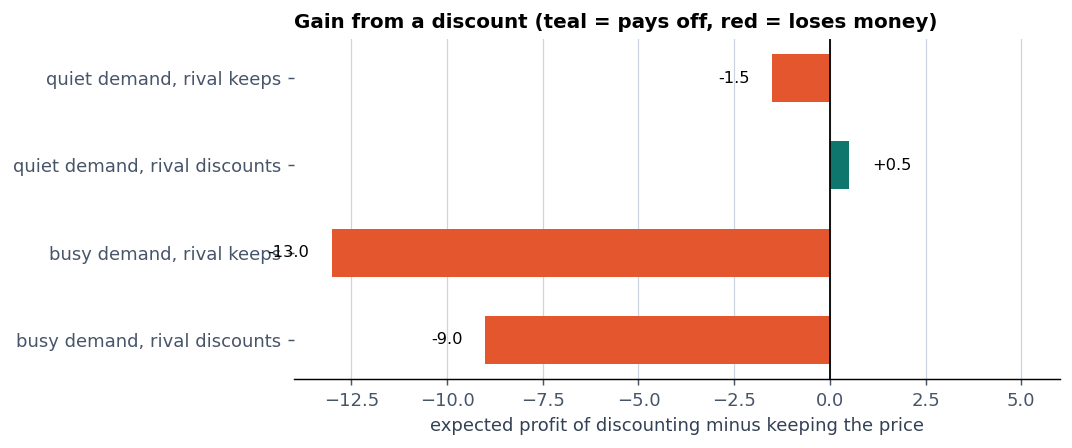

In [3]:
lab.run_expected_profit(cfg)

# the same numbers as a picture
scenarios = [(d, c) for d in (0, 1) for c in (0, 1)]
labels = [f"{'quiet' if d == 0 else 'busy'} demand\nrival {'discounts' if c else 'keeps'}" for d, c in scenarios]
keep = [lab.expected_profit(cfg, d, 0, c) for d, c in scenarios]
cut = [lab.expected_profit(cfg, d, 1, c) for d, c in scenarios]

gain = [c - k for k, c in zip(keep, cut)]
fig, ax = plt.subplots(figsize=(7.6, 3.4))
colors = [lab.TEAL if g > 0 else lab.CORAL for g in gain]
ax.barh([l.replace("\n", ", ") for l in labels], gain, color=colors, height=0.55)
for y, g in enumerate(gain):
    ax.text(g + (0.6 if g >= 0 else -0.6), y, f"{g:+.1f}", va="center", ha="left" if g >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=1)
ax.invert_yaxis()
ax.set_xlim(-14, 6)
ax.grid(axis="y", alpha=0)
ax.grid(axis="x", alpha=1)
ax.set_xlabel("expected profit of discounting minus keeping the price")
ax.set_title("Gain from a discount (teal = pays off, red = loses money)")
show_fig(fig)

**Reading the chart.** Keeping the price is better in three of the four situations. The one case where a discount pays (quiet demand while the rival is already discounting, +0.5) never occurs against the reference rule, because the rule never discounts in quiet periods.

A discount also has a **delayed price**: next step, if demand is busy, the rule copies our discount and our own profit falls from 55 to 45.

The best policy against the rule is therefore *never discount*, worth $0.5\cdot15+0.5\cdot55=35$ per step. Keep this number in mind - it is the yardstick for everything that follows.

## 3. The two sellers

**Rule-based seller.** Quiet demand → keep. Busy demand and the rival discounted last step → discount. Busy demand otherwise → keep. It never learns.

**Q-learning seller.** It owns a table $Q(s,a)$ with $4\times2=8$ entries, each answering *"how much total future profit do I expect if I play $a$ in situation $s$?"*. It plays the larger entry, except that with probability $\varepsilon$ it tries a random move (**exploration**). After every step it nudges one entry towards a fresh estimate:

$$Q(s,a)\;\leftarrow\;Q(s,a)+\alpha\Bigl[\underbrace{r+\gamma\max_{a'}Q(s',a')}_{\text{target}}-Q(s,a)\Bigr]$$

**Worked example (question 3).** $Q(s,a)=4$, $\alpha=0.1$, $r=6$, $\gamma=0.9$, $\max_{a'}Q(s',a')=5$.

target    = 6 + 0.9 x 5      = 10.5
TD error  = 10.5 - 4        = 6.5
new Q     = 4 + 0.1 x 6.5  = 4.65
TabularQSeller.update gives the same value: 4.65


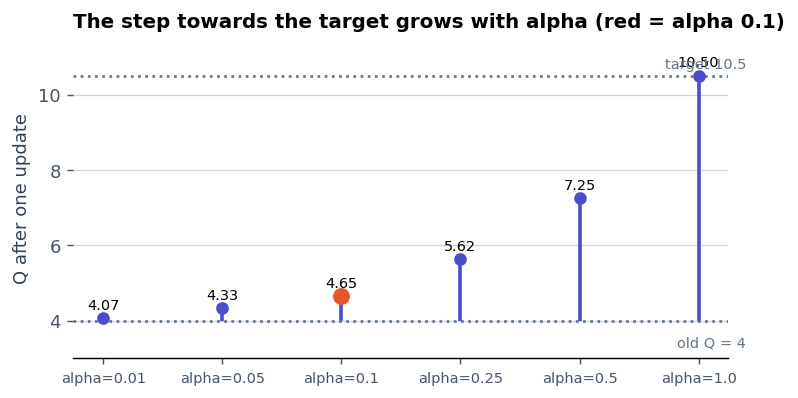

In [4]:
def td_step(q_sa, reward, best_next, lr, gamma):
    # one temporal-difference update, returned piece by piece
    target = reward + gamma * best_next
    td_error = target - q_sa
    return target, td_error, q_sa + lr * td_error


target, td_error, q_new = td_step(q_sa=4.0, reward=6.0, best_next=5.0, lr=0.1, gamma=0.9)
print(f"target    = 6 + 0.9 x 5      = {target}")
print(f"TD error  = {target} - 4        = {td_error}")
print(f"new Q     = 4 + 0.1 x {td_error}  = {q_new:.2f}")

# cross-check against the real agent class
seller = lab.TabularQSeller(lr=0.1, gamma=0.9, epsilon=0.0, seed=0)
seller.q[0, 0, 1] = 4.0
seller.q[1, 0, :] = [5.0, 1.0]
seller.update((0, 0), 1, 6.0, (1, 0))
assert abs(seller.q[0, 0, 1] - q_new) < 1e-12
print("TabularQSeller.update gives the same value:", round(float(seller.q[0, 0, 1]), 2))

# what would other learning rates have done?
rates = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0]
new_q = [4 + r * td_error for r in rates]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.vlines(range(len(rates)), 4, new_q, color=lab.INDIGO, lw=2)
ax.scatter(range(len(rates)), new_q, color=lab.INDIGO, zorder=3)
ax.scatter([2], [q_new], color=lab.CORAL, zorder=4, s=70)
for i, v in enumerate(new_q):
    ax.text(i, v + 0.25, f"{v:.2f}", ha="center", fontsize=8)
ax.axhline(4, color=lab.SLATE, ls=":")
ax.axhline(target, color=lab.SLATE, ls=":")
ax.text(len(rates) - 0.6, target + 0.2, "target 10.5", ha="right", fontsize=8, color=lab.SLATE)
ax.text(len(rates) - 0.6, 4 - 0.7, "old Q = 4", ha="right", fontsize=8, color=lab.SLATE)
ax.set_xticks(range(len(rates)), [f"alpha={r}" for r in rates], fontsize=8)
ax.set_ylim(3, 11.5)
ax.set_ylabel("Q after one update")
ax.set_title("The step towards the target grows with alpha (red = alpha 0.1)")
show_fig(fig)

The outcome (10.5) beat the expectation (4), so $Q$ rises - but only by 10 % of the gap, to 4.65. A single lucky step is not taken at face value. With $\alpha=1$ the table would simply be overwritten by the latest sample; with $\alpha=0.01$ it would barely move (4.065).

## 4. Experiments A and B - the baseline run (seed 42)

We train the Q-learning seller for 5 000 episodes × 20 steps against the rule-based seller. **Evaluation is a separate step:** the Q-table is frozen, $\varepsilon=0$, and the market uses a brand-new seed.

For a *fair* comparison the rule-based seller is also evaluated in **seat 0**, against the **same rival**, with the **same seed**. Because the market draws the same number of random values per step whatever the moves are, both runs experience exactly the same demand sequence.

In [5]:
baseline_seller = lab.run_baseline(cfg)


------------------------------------------------------------------------
 Experiments A and B: baseline run (seed 42)
------------------------------------------------------------------------
RL vs Rule    seat 0  RL         total=  351,275  mean/step=35.127  discounts=0  keeps=10000
RL vs Rule    seat 1  Rule-based total=  349,685  mean/step=34.968  discounts=0  keeps=10000
Rule vs Rule  seat 0  Rule-based total=  351,275  mean/step=35.127  discounts=0  keeps=10000
Rule vs Rule  seat 1  Rule-based total=  349,685  mean/step=34.968  discounts=0  keeps=10000
Baseline Q-table
Q[demand, rival_last_action, action]; action 0 = no discount, 1 = discount
  state=(0, 0) | Q0= 228.3024 | Q1= 178.8494 | visits=(33659, 12490) | greedy=NO DISCOUNT
  state=(0, 1) | Q0= 177.9920 | Q1= 207.2051 | visits=(2501, 1522) | greedy=DISCOUNT
  state=(1, 0) | Q0= 246.8799 | Q1= 235.2338 | visits=(42848, 3103) | greedy=NO DISCOUNT
  state=(1, 1) | Q0= 211.4198 | Q1= 242.9629 | visits=(3468, 409) | greedy=DISCO

In [6]:
print_table("baseline_evaluation.csv",
            ["match", "agent", "seat", "total_reward", "mean_reward_per_step",
             "discount_actions", "no_discount_actions"])

match        | agent      | seat | total_reward | mean_reward_per_step | discount_actions | no_discount_actions
-------------+------------+------+--------------+----------------------+------------------+--------------------
RL vs Rule   | RL         | 0    | 351275.000   | 35.127               | 0                | 10000              
RL vs Rule   | Rule-based | 1    | 349685.000   | 34.968               | 0                | 10000              
Rule vs Rule | Rule-based | 0    | 351275.000   | 35.127               | 0                | 10000              
Rule vs Rule | Rule-based | 1    | 349685.000   | 34.968               | 0                | 10000              


In evaluation the Q-learning seller **never discounts** and collects exactly the same total as the rule-based seller in the same seat - the two policies chose identical moves on all 10 000 steps. The Q-table does say "discount" in the two states with $c=1$, but those states are rarely visited (the rival only discounts after we do) and they are never reached in greedy play. The next cell visualises this.

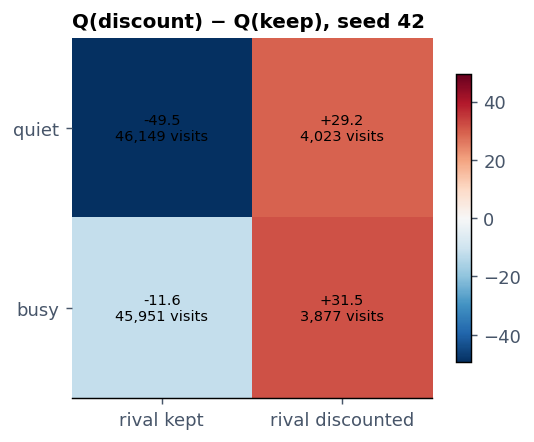

In [7]:
q = baseline_seller.q
advantage = q[:, :, 1] - q[:, :, 0]          # Q(discount) - Q(keep) for each state (d, c)
limit = np.abs(advantage).max()

fig, ax = plt.subplots(figsize=(4.8, 3.6))
img = ax.imshow(advantage, cmap="RdBu_r", vmin=-limit, vmax=limit)
for d in range(2):
    for c in range(2):
        visits = int(baseline_seller.visits[d, c].sum())
        ax.text(c, d, f"{advantage[d, c]:+.1f}\n{visits:,} visits", ha="center", va="center", fontsize=8)
ax.set_xticks([0, 1], ["rival kept", "rival discounted"])
ax.set_yticks([0, 1], ["quiet", "busy"])
ax.set_title("Q(discount) − Q(keep), seed 42")
ax.grid(False)
fig.colorbar(img, ax=ax, shrink=0.8)
show_fig(fig)

Red cells favour discounting, blue cells favour keeping. Both red cells sit in the right-hand column, which is visited in only about 4 % of the training steps.

### The learning curve (experiment B)
Top panel: for every block of $K=100$ episodes, the full range of single-episode rewards (pale band), the middle 50 % (darker band) and the block mean. Bottom panel: how many times the greedy policy flipped inside each block (bars) and how often the learner discounted (line).

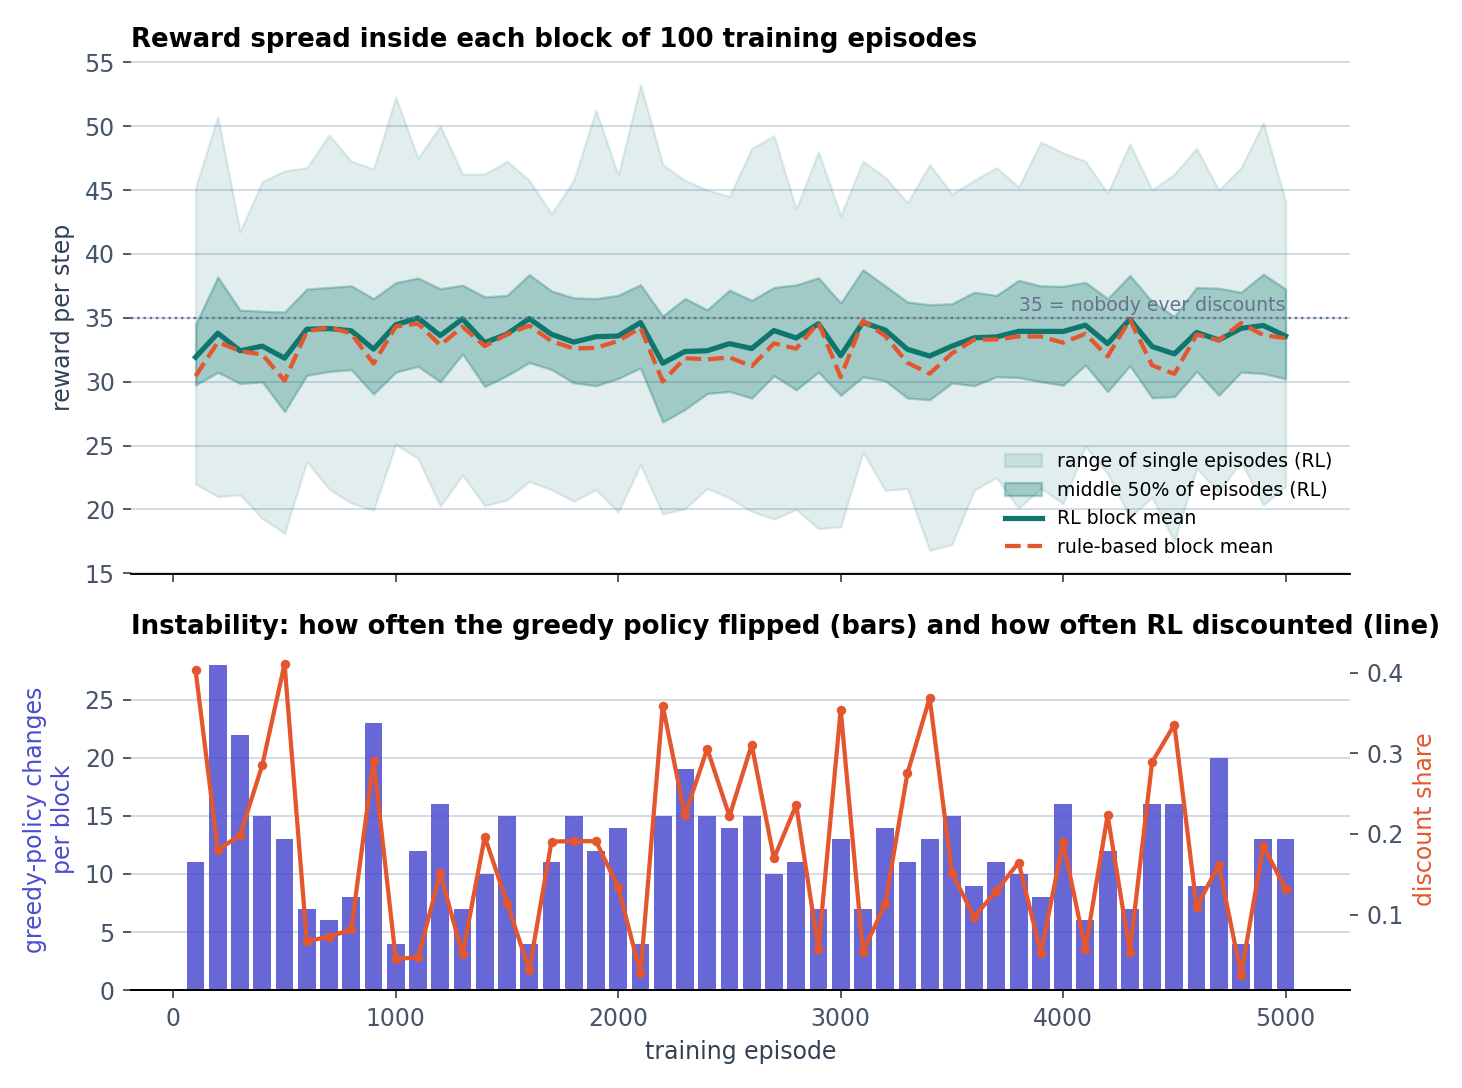

In [8]:
show_png("fig_baseline_training.png")

The block mean climbs during roughly the first 500 episodes and then **keeps wandering** between about 31 and 35, while single episodes stay spread over a wide band because demand is random. Exploration has already hit its floor ($\varepsilon=0.02$), yet the bars in the lower panel show that the *greedy policy itself* keeps flipping (606 changes in total), and the discount line moves with them. A rising curve is therefore not proof of convergence.

Each point below is one of the 500 evaluation episodes: its x-value is what the rule-based seller earned, its y-value what the RL seller earned on the very same demand sequence. Every point sits on the diagonal - the paired comparison at work.

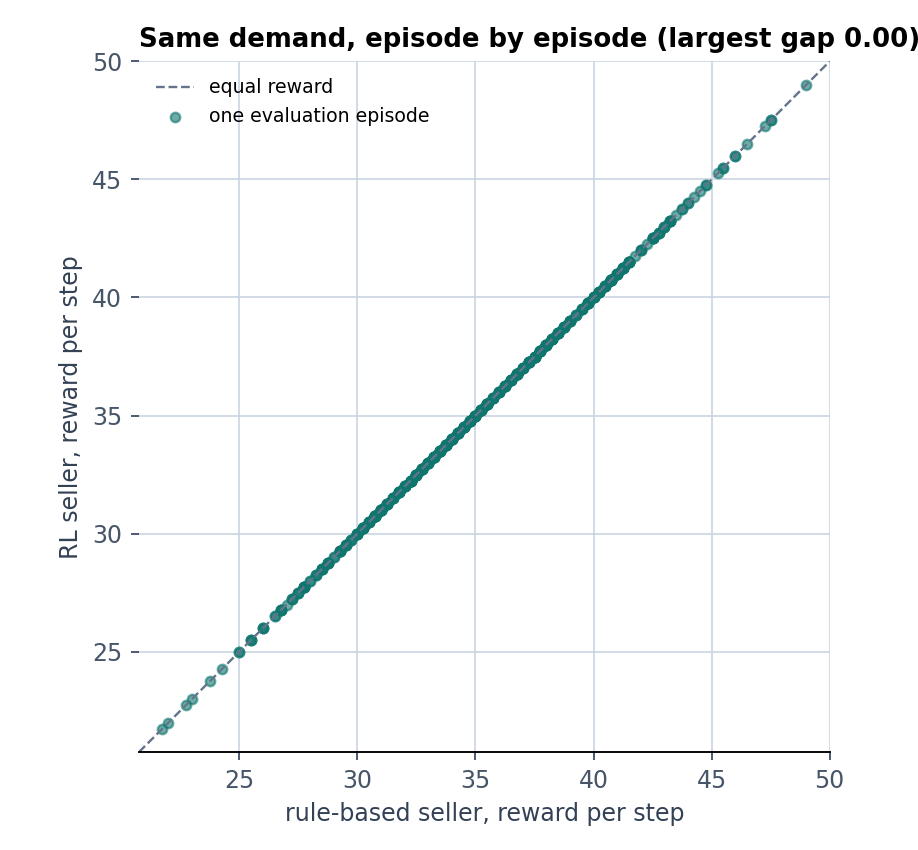

In [9]:
show_png("fig_baseline_eval_paired.png")

## 5. Experiment C - learning rate (10 seeds per setting)

We repeat the whole experiment with $\alpha\in\{0.01,\,0.10,\,0.50\}$. Left: a heatmap of the training reward per block (darker = more profit), one row per learning rate. Right: how many times the greedy policy changed per run (log scale).


------------------------------------------------------------------------
 Experiment C: learning rate
------------------------------------------------------------------------
{'configuration': 'alpha=0.01', 'n_seeds': 10, 'eval_mean_reward': 33.633889999999994, 'eval_std_across_seeds': 3.1930351929194623, 'train_mean_reward': 32.441345999999996, 'train_std_across_seeds': 2.2732112841343084, 'eval_discount_rate': 0.14977000000000001, 'seeds_with_never_discount_policy': 1, 'mean_policy_flips': 21.5}
{'configuration': 'alpha=0.10', 'n_seeds': 10, 'eval_mean_reward': 34.38976, 'eval_std_across_seeds': 1.2392711443963071, 'train_mean_reward': 33.608051, 'train_std_across_seeds': 0.1438560608115699, 'eval_discount_rate': 0.09098999999999999, 'seeds_with_never_discount_policy': 4, 'mean_policy_flips': 584.1}
{'configuration': 'alpha=0.50', 'n_seeds': 10, 'eval_mean_reward': 32.04455, 'eval_std_across_seeds': 3.5090174209535574, 'train_mean_reward': 31.811658000000005, 'train_std_across_seeds

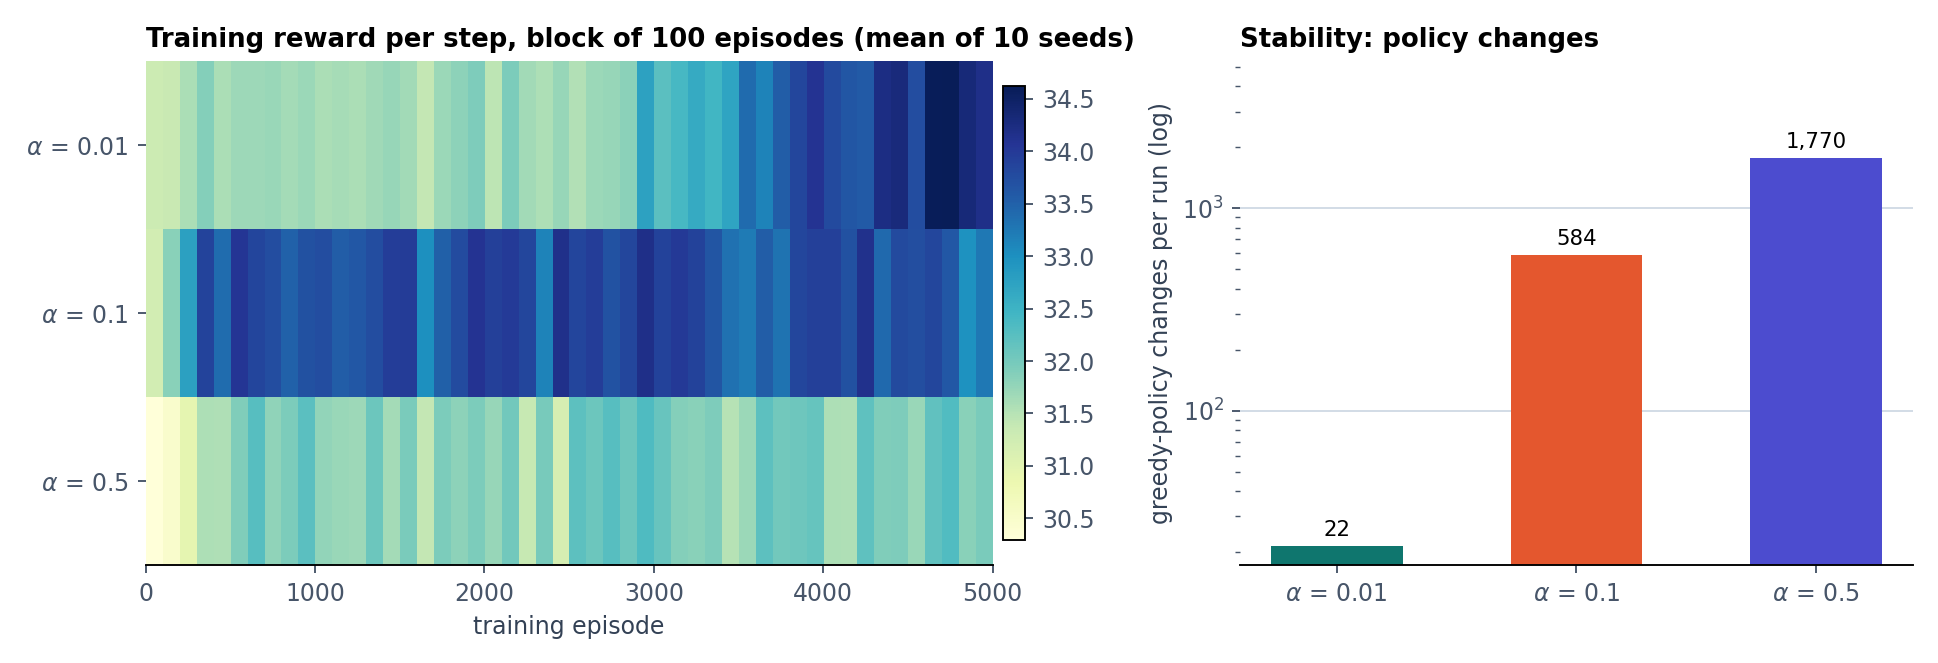

alpha | eval_mean_reward | eval_std_across_seeds | train_mean_reward | eval_discount_rate | seeds_with_never_discount_policy | mean_policy_flips
------+------------------+-----------------------+-------------------+--------------------+----------------------------------+------------------
0.010 | 33.634           | 3.193                 | 32.441            | 0.150              | 1                                | 21.500           
0.100 | 34.390           | 1.239                 | 33.608            | 0.091              | 4                                | 584.100          
0.500 | 32.045           | 3.509                 | 31.812            | 0.287              | 3                                | 1769.900         


In [10]:
lr_results = lab.run_learning_rate(cfg)
show_png("fig_learning_rate.png")
print_table("learning_rate_comparison.csv",
            ["alpha", "eval_mean_reward", "eval_std_across_seeds", "train_mean_reward",
             "eval_discount_rate", "seeds_with_never_discount_policy", "mean_policy_flips"])

Reading the plots: the α = 0.10 row reaches the dark colours within about 500 episodes; α = 0.01 only gets there in the last ~1 500 episodes (it is still climbing when training stops); α = 0.50 never does. The log-scale bars show that stability differs by almost two orders of magnitude.

* **α = 0.01** - very calm (few policy changes) but slow. Q-values are still climbing from 0, so whichever action happened to be tried more often looks better just because it received more updates.
* **α = 0.10** - best and most consistent.
* **α = 0.50** - each new sample moves Q a great deal. With noisy sales the two actions get ranked almost at random: about 1 770 policy changes per run.

## 6. Experiment D - exploration (10 seeds per setting)

Four schedules: the reference decay (0.20 → 0.02), a small fixed ε = 0.05, a large fixed ε = 0.30 and no exploration at all. Left: greedy evaluation reward of every single seed (green = good, red = bad). Right: reward while training against reward in evaluation, one dot per seed.


------------------------------------------------------------------------
 Experiment D: exploration schedules
------------------------------------------------------------------------
{'configuration': 'Reference decay 0.20→0.02', 'n_seeds': 10, 'eval_mean_reward': 34.38976, 'eval_std_across_seeds': 1.2392711443963071, 'train_mean_reward': 33.608051, 'train_std_across_seeds': 0.1438560608115699, 'eval_discount_rate': 0.09098999999999999, 'seeds_with_never_discount_policy': 4, 'mean_policy_flips': 584.1}
{'configuration': 'Fixed ε = 0.05', 'n_seeds': 10, 'eval_mean_reward': 34.12224, 'eval_std_across_seeds': 1.346495990174332, 'train_mean_reward': 32.909012, 'train_std_across_seeds': 0.20466913395906872, 'eval_discount_rate': 0.13189, 'seeds_with_never_discount_policy': 4, 'mean_policy_flips': 960.1}
{'configuration': 'Fixed ε = 0.30', 'n_seeds': 10, 'eval_mean_reward': 29.65407, 'eval_std_across_seeds': 3.2636494232513535, 'train_mean_reward': 30.887582, 'train_std_across_seeds': 0.100

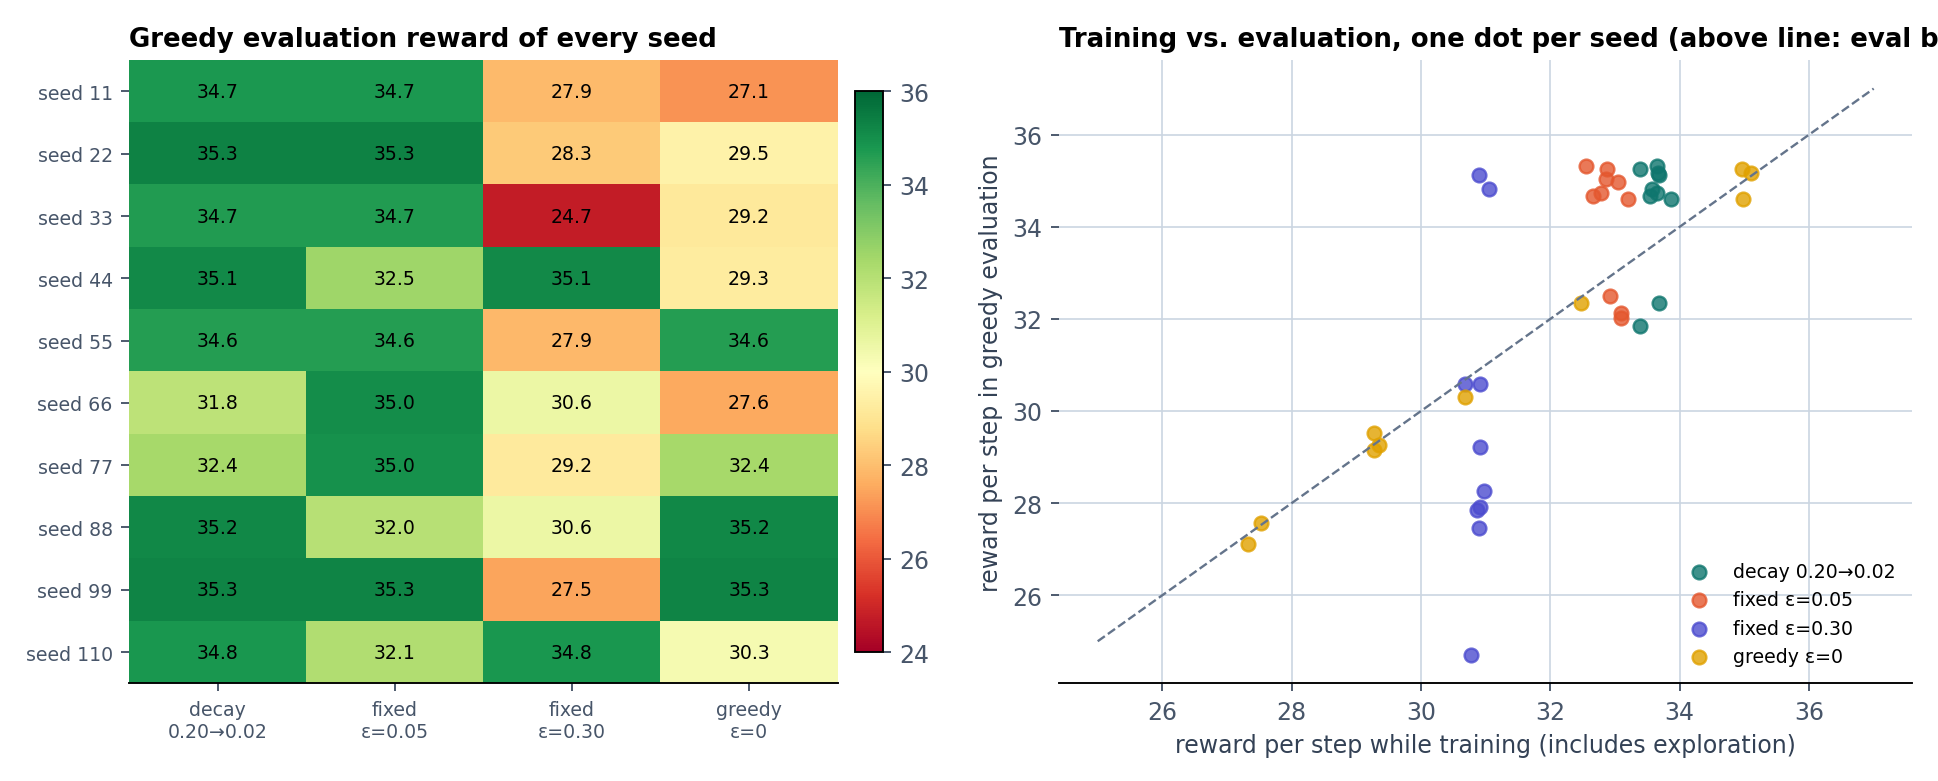

configuration             | train_mean_reward | eval_mean_reward | eval_std_across_seeds | eval_discount_rate | seeds_with_never_discount_policy
--------------------------+-------------------+------------------+-----------------------+--------------------+---------------------------------
Reference decay 0.20→0.02 | 33.608            | 34.390           | 1.239                 | 0.091              | 4                               
Fixed ε = 0.05            | 32.909            | 34.122           | 1.346                 | 0.132              | 4                               
Fixed ε = 0.30            | 30.888            | 29.654           | 3.264                 | 0.495              | 0                               
Greedy, ε = 0             | 31.094            | 31.029           | 3.099                 | 0.436              | 3                               


In [11]:
expl_results = lab.run_exploration(cfg)
show_png("fig_exploration.png")
print_table("exploration_comparison.csv",
            ["configuration", "train_mean_reward", "eval_mean_reward", "eval_std_across_seeds",
             "eval_discount_rate", "seeds_with_never_discount_policy"])

* **Too much exploration (ε = 0.30)** pays for random discounts during training, and the values it learns are so noisy that the final policy is poor too.
* **No exploration (ε = 0)**: whatever move is tried first in a state wins for ever (0 policy changes). Whether that move was any good is pure luck.
* **Decaying schedule** explores early and exploits later - best training *and* best evaluation reward.

## 7. Experiment E - fair comparison over 10 seeds


------------------------------------------------------------------------
 Experiment E: paired comparison over 10 seeds
------------------------------------------------------------------------
RL, baseline ($\alpha=0.10$, decaying $\varepsilon$)    mean=34.390  std=1.239  disc=0.091
RL, low learning rate ($\alpha=0.01$)                   mean=33.634  std=3.193  disc=0.150
RL, high learning rate ($\alpha=0.50$)                  mean=32.045  std=3.509  disc=0.287
RL, fixed $\varepsilon=0.05$                            mean=34.122  std=1.346  disc=0.132
RL, fixed $\varepsilon=0.30$                            mean=29.654  std=3.264  disc=0.495
RL, greedy $\varepsilon=0$                              mean=31.029  std=3.099  disc=0.436
Rule-based                                              mean=34.970  std=0.253  disc=0.000
Paired gap RL - Rule: mean=-0.580  std=1.231


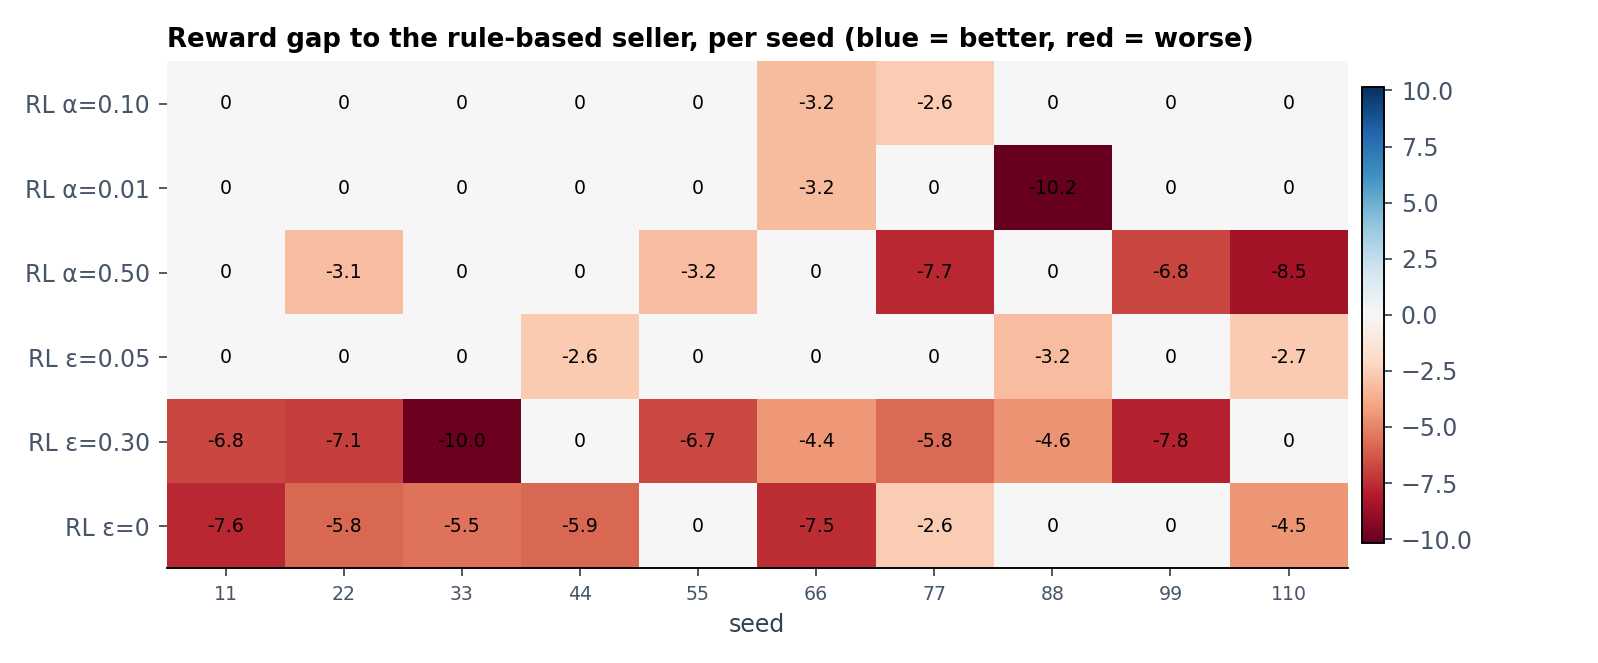

seed | difference
-----+-----------
11   | 0.000     
22   | 0.000     
33   | 0.000     
44   | 0.000     
55   | 0.000     
66   | -3.194    
77   | -2.611    
88   | 0.000     
99   | 0.000     
110  | 0.000     


In [12]:
lab.run_fair_comparison(cfg, lr_results, expl_results)
show_png("fig_gap_to_rule.png")
print_table("paired_difference_rl_minus_rule.csv")

The rule-based seller already plays the best response here, so learning can at best tie. It does tie in 8 of 10 seeds (difference exactly 0) and is about 3 per step worse in the other two. Looking only at seed 42 would have hidden this completely.

## 8. Question 8 - what if both sellers learn?


------------------------------------------------------------------------
 Question 8: two sellers that both learn
------------------------------------------------------------------------
policy_flips_vs_rule                mean=584.100  std=24.538
policy_flips_vs_learning_rl         mean=589.400  std=25.369
rl_vs_rl_eval_reward_seat0          mean=33.625  std=1.858
rl_vs_rl_eval_reward_seat1          mean=33.616  std=2.005
rl_vs_rl_discount_rate_seat0        mean=0.171  std=0.236
rl_vs_rl_discount_rate_seat1        mean=0.212  std=0.299
late_flips_vs_rule                  mean=267.500  std=28.524
late_flips_vs_learning_rl           mean=272.600  std=28.691


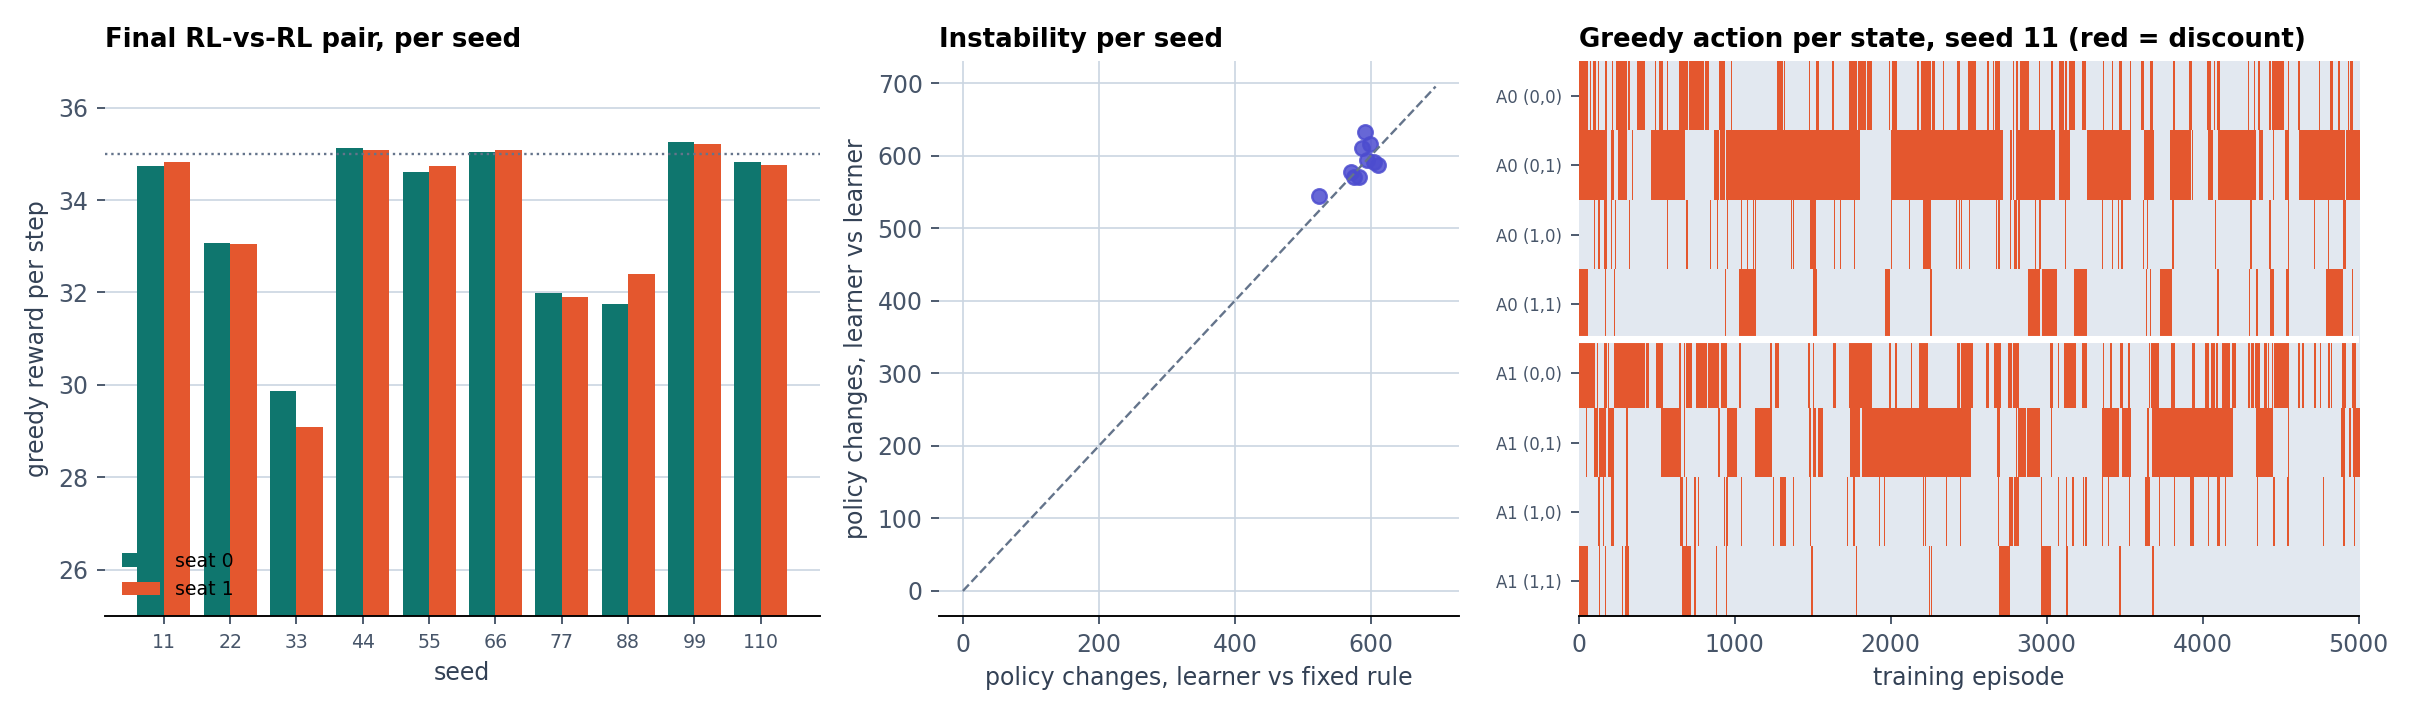

In [13]:
lab.run_two_learners(cfg)
show_png("fig_two_learners.png")

When the rival learns as well, the world each learner faces keeps changing underneath it (**non-stationarity**). Left: the final greedy reward of both seats, seed by seed - the pairs where a bar falls well below 35 are the ones in which a seller still discounts (4 of 10). Middle: policy changes per seed against a fixed rival (x) and against a learning rival (y); points near the diagonal mean the rival's learning made little difference, which tells us that in this small problem the noise caused by a constant $\alpha$ already dominates. Right: the greedy policy of each learner over time - horizontal stripes show how long a state keeps its choice.

## 9. Question 9 - change the market: an aggressive rival

The competitor now discounts **whenever demand is busy**. Never discounting is still optimal (expected 30), but the rule-based seller's "match the rival" reflex now fires on 25 % of steps and costs 9 each time, giving an expected 27.75.


------------------------------------------------------------------------
 Question 9: the rival becomes aggressive
------------------------------------------------------------------------
{'agent': 'RL retrained against the aggressive competitor', 'eval_mean': 28.75907, 'eval_std': 1.189018880375282, 'discount_rate': 0.32206}
{'agent': 'RL trained on the reference market (not retrained)', 'eval_mean': 29.314520000000005, 'eval_std': 0.9223910845671096, 'discount_rate': nan}
{'agent': 'Rule-based', 'eval_mean': 27.84178, 'eval_std': 0.15462921816756073, 'discount_rate': 0.23687999999999998}
Paired gap RL - Rule (aggressive market): mean=0.917  std=1.204
agent                                              | eval_mean | eval_std | discount_rate
---------------------------------------------------+-----------+----------+--------------
RL retrained against the aggressive competitor     | 28.759    | 1.189    | 0.322        
RL trained on the reference market (not retrained) | 29.315    | 0.9

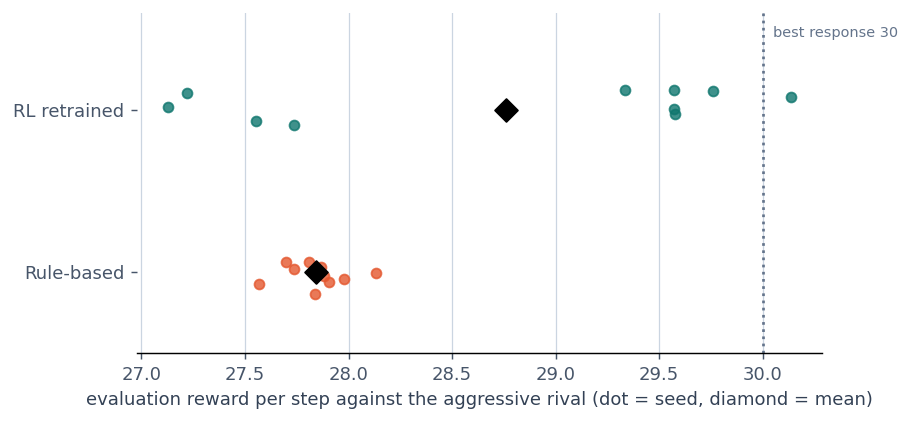

In [14]:
aggressive_table = lab.run_aggressive_market(cfg)

def read_rows(name):
    with open(lab.RESULTS / name, encoding="utf-8") as fh:
        return list(csv.DictReader(fh))

print_table("modification_aggressive.csv")

per_seed = read_rows("modification_aggressive_per_seed.csv")
groups = {"RL retrained": [float(r["eval_mean_reward_per_step"]) for r in per_seed if r["configuration"] == "RL vs Aggressive"],
          "Rule-based": [float(r["eval_mean_reward_per_step"]) for r in per_seed if r["configuration"] == "Rule-based"]}
fig, ax = plt.subplots(figsize=(6.8, 3.4))
rng = np.random.default_rng(3)
for i, (name, vals) in enumerate(groups.items()):
    ax.scatter(vals, i + rng.uniform(-0.15, 0.15, len(vals)), s=30, color=[lab.TEAL, lab.CORAL][i], alpha=0.8)
    ax.scatter([np.mean(vals)], [i], marker="D", s=80, color="black", zorder=4)
ax.axvline(30, color=lab.SLATE, ls=":")
ax.text(30.05, -0.45, "best response 30", fontsize=8, color=lab.SLATE)
ax.set_yticks(range(len(groups)), list(groups))
ax.set_ylim(len(groups) - 0.5, -0.6)
ax.grid(axis="y", alpha=0)
ax.grid(axis="x", alpha=1)
ax.set_xlabel("evaluation reward per step against the aggressive rival (dot = seed, diamond = mean)")
show_fig(fig)

The fixed rule drops to 27.84 (the arithmetic predicted 27.75), and both learning variants do better on average. A rule that fits one market can be the weakest choice in another.

## 10. Question 10 - a sturdier learner

Proposal: train against a **pool of rivals** (rule, aggressive, tit-for-tat, always-discount, random) with a step size $\alpha=1/N(s,a)$ that shrinks with experience. A second variant also includes the seller's **own previous move** in the state. Every seller is tested against every rival; the diamonds in the chart and the last row of the table are the best achievable expectation computed from the model.


------------------------------------------------------------------------
 Question 10: robustness against a pool of rivals
------------------------------------------------------------------------
Rule-based                                     vs rule             34.984 ± 0.272
Rule-based                                     vs aggressive       27.888 ± 0.137
Rule-based                                     vs tit_for_tat      34.984 ± 0.272
Rule-based                                     vs always_discount  23.230 ± 0.164
Rule-based                                     vs random           28.613 ± 0.213
RL baseline (trained vs rule)                  vs rule             34.418 ± 1.253
RL baseline (trained vs rule)                  vs aggressive       29.321 ± 0.846
RL baseline (trained vs rule)                  vs tit_for_tat      34.330 ± 1.459
RL baseline (trained vs rule)                  vs always_discount  26.701 ± 1.741
RL baseline (trained vs rule)                  vs random         

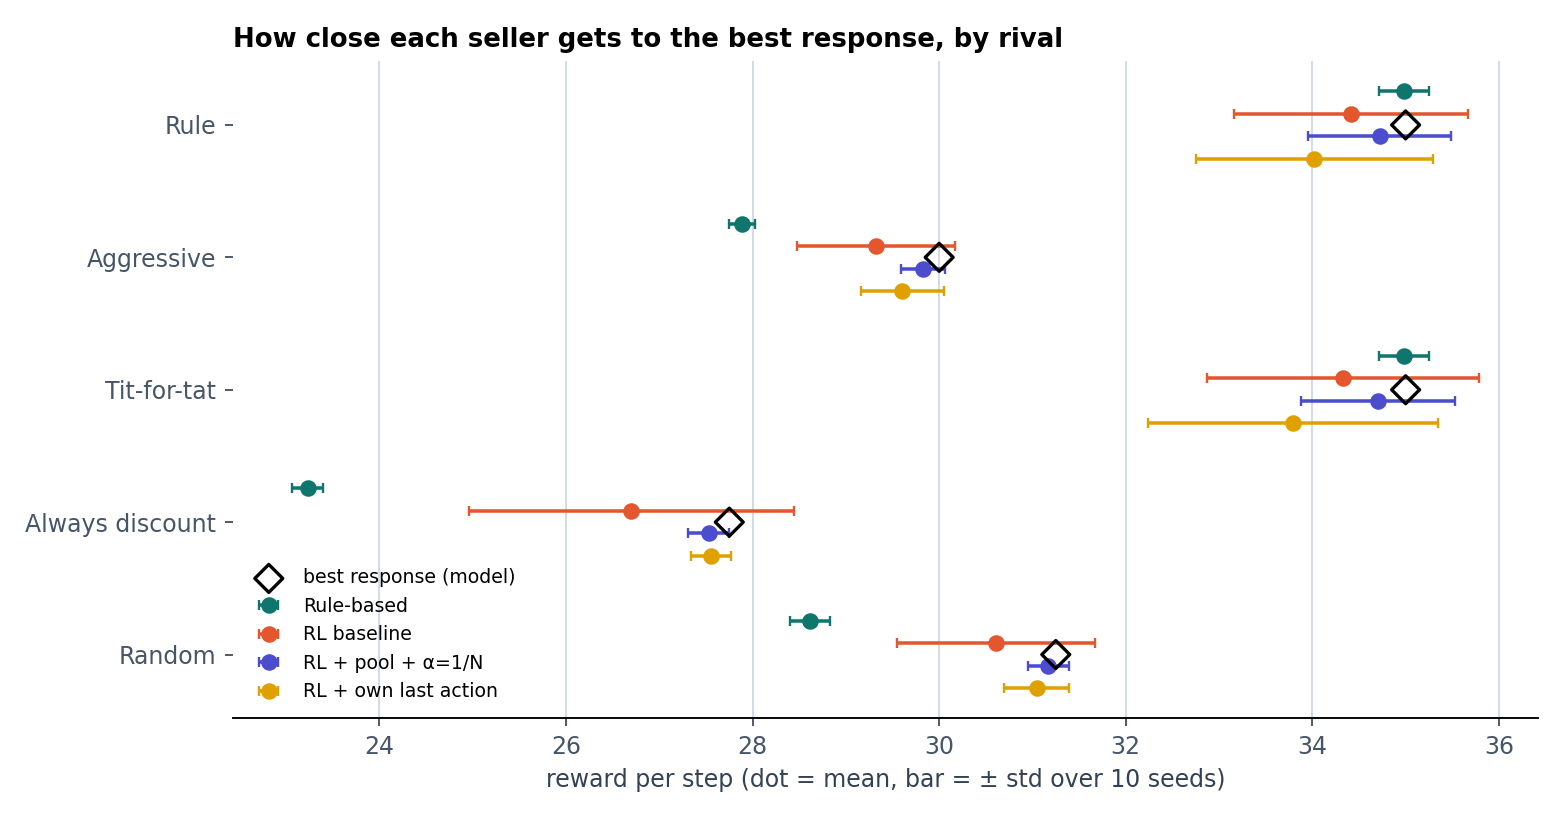

agent                                        | opponent        | mean   | std  
---------------------------------------------+-----------------+--------+------
Rule-based                                   | rule            | 34.984 | 0.272
Rule-based                                   | aggressive      | 27.888 | 0.137
Rule-based                                   | tit_for_tat     | 34.984 | 0.272
Rule-based                                   | always_discount | 23.230 | 0.164
Rule-based                                   | random          | 28.613 | 0.213
RL baseline (trained vs rule)                | rule            | 34.418 | 1.253
RL baseline (trained vs rule)                | aggressive      | 29.321 | 0.846
RL baseline (trained vs rule)                | tit_for_tat     | 34.330 | 1.459
RL baseline (trained vs rule)                | always_discount | 26.701 | 1.741
RL baseline (trained vs rule)                | random          | 30.609 | 1.062
RL + opponent pool + α=1/N              

In [15]:
lab.run_robustness(cfg)
show_png("fig_robustness_dots.png")
print_table("robustness_summary.csv", ["agent", "opponent", "mean", "std"])

* The **rule-based seller** is flawless against the rule and tit-for-tat, but loses 4.5 per step against an always-discounting rival.
* **Opponent pool + α = 1/N** ends up within 0.1-0.3 of the best response against every rival - the most robust seller we tested.
* Adding the **own previous move** did *not* help here. The idea is sensible, yet the measurement does not support it, so it is reported as a negative result.

## 11. Take-aways

The summary below is computed from the CSV files that the cells above just wrote.

In [16]:
def read_csv(name):
    with open(lab.RESULTS / name, encoding="utf-8") as fh:
        return list(csv.DictReader(fh))


robust = read_csv("robustness_summary.csv")
def rival_mean(agent, rival):
    return next(float(r["mean"]) for r in robust if r["agent"] == agent and r["opponent"] == rival)

agents = ["Rule-based", "RL baseline (trained vs rule)", "RL + opponent pool + α=1/N",
          "Improved RL (+ own previous action in state)", "Best response (model)"]
rows = []
for a in agents:
    per_rival = [rival_mean(a, r) for r in lab.ROBUSTNESS_RIVALS]
    rows.append((a, rival_mean(a, "rule"), rival_mean(a, "aggressive"),
                 float(np.mean(per_rival)), float(np.min(per_rival))))

print(f"{'seller':<46}{'vs rule':>9}{'vs aggr.':>10}{'average':>9}{'worst':>8}")
for a, v_rule, v_aggr, avg, worst in rows:
    print(f"{a:<46}{v_rule:>9.2f}{v_aggr:>10.2f}{avg:>9.2f}{worst:>8.2f}")

summary = {r["configuration"]: r for r in read_csv("multi_seed_summary.csv")}
rl_ref = next(v for k, v in summary.items() if k.startswith("RL, baseline"))
rule_ref = summary["Rule-based"]
print()
print(f"Reference market, 10 seeds: RL {float(rl_ref['eval_mean_reward']):.2f} ± {float(rl_ref['eval_std_across_seeds']):.2f}"
      f"  vs  rule {float(rule_ref['eval_mean_reward']):.2f} ± {float(rule_ref['eval_std_across_seeds']):.2f}")

seller                                          vs rule  vs aggr.  average   worst
Rule-based                                        34.98     27.89    29.94   23.23
RL baseline (trained vs rule)                     34.42     29.32    31.08   26.70
RL + opponent pool + α=1/N                        34.72     29.83    31.59   27.53
Improved RL (+ own previous action in state)      34.02     29.61    31.21   27.56
Best response (model)                             35.00     30.00    31.80   27.75

Reference market, 10 seeds: RL 34.39 ± 1.24  vs  rule 34.97 ± 0.25


| | Learning seller | Rule-based seller |
|---|---|---|
| Reference market (10 seeds) | 34.39 ± 1.24 | 34.97 ± 0.25 |
| Aggressive rival | 28.76 (retrained) / 29.31 (carried over) | 27.84 |
| Average over 5 rival types | 31.08 (31.59 with pool + α = 1/N) | 29.94 |

The hand-written rule wins where its assumptions hold; the learners win when the market shifts. A rule-based seller is cheap, predictable and auditable; a learning seller costs training time and varies from seed to seed, but it can adapt without a developer rewriting it.

The full discussion and the answers to all ten questions are in `report/agent02.pdf`.